In [1]:
import pandas as pd

df = pd.read_csv("sentiment_data_cleaned.csv")
df.head()

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,Enjoying a beautiful day at the park!,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,Usa,2023,1,15,12
1,Traffic was terrible this morning.,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,Just finished an amazing workout! 💪,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,Usa,2023,1,15,15
3,Excited about the upcoming weekend getaway!,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,Uk,2023,1,15,18
4,Trying out a new recipe for dinner tonight.,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [2]:
df["Sentiment"].value_counts()

Sentiment
Positive       45
Joy            44
Excitement     37
Neutral        18
Contentment    18
               ..
Suffering       1
Marvel          1
Spark           1
Immersion       1
Intrigue        1
Name: count, Length: 191, dtype: int64

In [3]:
import nltk

nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Personal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Personal\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Personal\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Personal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [4]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [5]:
def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

In [6]:
df["clean_text"] = df["Text"].apply(preprocess_text)
df[["Text", "clean_text"]].head()

,Text,clean_text
0,Enjoying a beautiful day at the park!,enjoying beautiful day park
1,Traffic was terrible this morning.,traffic terrible morning
2,Just finished an amazing workout! 💪,finished amazing workout
3,Excited about the upcoming weekend getaway!,excited upcoming weekend getaway
4,Trying out a new recipe for dinner tonight.,trying new recipe dinner tonight


In [7]:
from textblob import TextBlob

def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

df["predicted_sentiment"] = df["clean_text"].apply(get_sentiment)

In [9]:
!pip install textblob

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for textblob from https://files.pythonhosted.org/packages/6b/7f/f4c3c1f86d80d76de7e94b1ed6d2712bd541bf4d0579cab34d20b39a7706/textblob-0.20.1-py3-none-any.whl.metadata
  Obtaining dependency information for nltk>=3.9 from https://files.pythonhosted.org/packages/b6/6d/ebd2af4640b12168fdf0cb74b6118df2f32a2f62ec7e0c06fbfd80706639/nltk-3.10.3-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
    --------------------------------------- 10.2/625.0 kB ? eta -:--:--
    --------------------------------------- 10.2/625.0 kB ? eta -:--:--
    --------------------------------------- 10.2/625.0 kB ? eta -:--:--
   -- ------------------------------------ 41.0/625.0 kB 245.8 kB/s eta 0:00:03
   -- ------------------------------------ 41.0/625.0 kB 245.8 kB/s eta 0:00:03
   ---------- --------------------------- 174.1/625.0 kB 700.2 kB/s eta 0:

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [8]:
def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

df["predicted_sentiment"] = df["clean_text"].apply(get_sentiment)
df["predicted_sentiment"].value_counts()

predicted_sentiment
Neutral     384
Positive    240
Negative     83
Name: count, dtype: int64

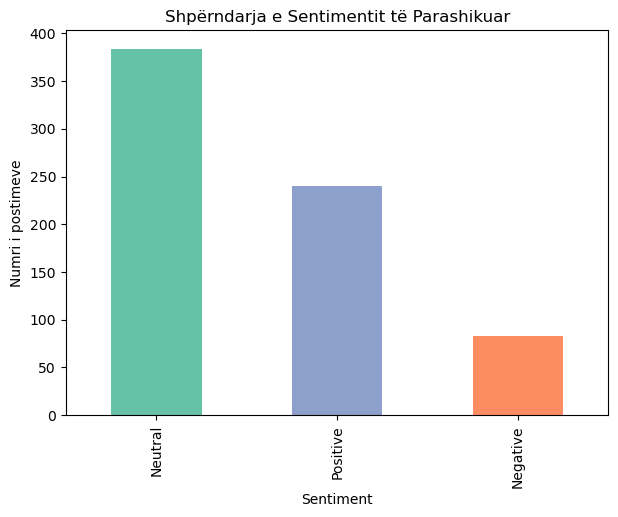

In [9]:
import matplotlib.pyplot as plt

sentiment_counts = df["predicted_sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar", color=["#66c2a5", "#8da0cb", "#fc8d62"])
plt.title("Shpërndarja e Sentimentit të Parashikuar")
plt.xlabel("Sentiment")
plt.ylabel("Numri i postimeve")
plt.savefig("nlp_sentiment_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

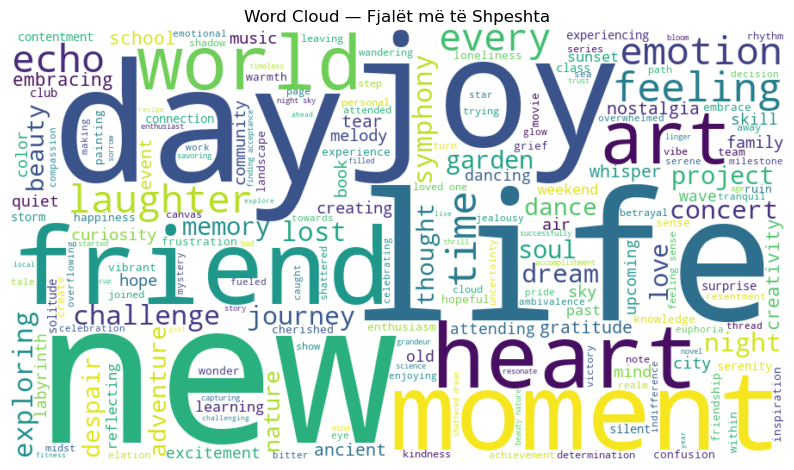

In [12]:
from wordcloud import WordCloud

all_text = " ".join(df["clean_text"])

wordcloud = WordCloud(width=900, height=500, background_color="white").generate(all_text)

plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Fjalët më të Shpeshta")
plt.savefig("nlp_wordcloud.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
!pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for wordcloud from https://files.pythonhosted.org/packages/45/70/0041966d469dec79036ad3962b83b007004b842531ee7c41bdba61310eb6/wordcloud-1.9.6-cp311-cp311-win_amd64.whl.metadata
   ---------------------------------------- 0.0/306.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/306.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/306.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/306.1 kB ? eta -:--:--
   ----- --------------------------------- 41.0/306.1 kB 281.8 kB/s eta 0:00:01
   ----- --------------------------------- 41.0/306.1 kB 281.8 kB/s eta 0:00:01
   ------------- ------------------------ 112.6/306.1 kB 504.4 kB/s eta 0:00:01
   -------------------------------------- - 297.0/306.1 kB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 306.1/306.1 kB 1.1 MB/s eta 0:00:00


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


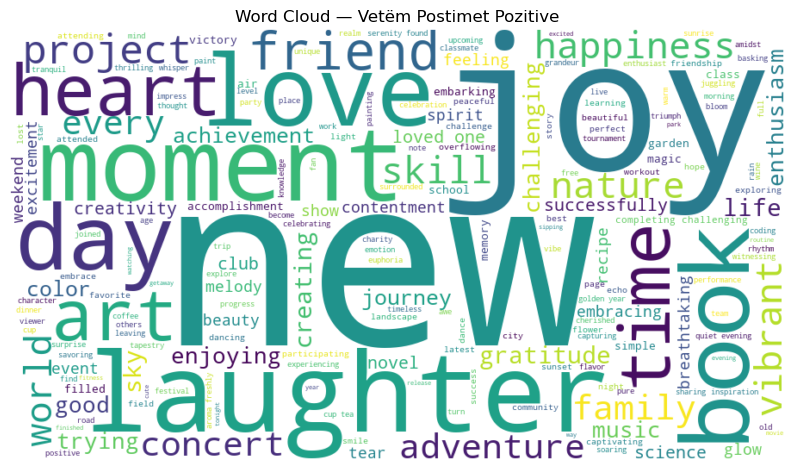

In [13]:
positive_text = " ".join(df[df["predicted_sentiment"] == "Positive"]["clean_text"])
wordcloud_pos = WordCloud(width=900, height=500, background_color="white").generate(positive_text)

plt.figure(figsize=(10, 6))
plt.imshow(wordcloud_pos, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Vetëm Postimet Pozitive")
plt.savefig("nlp_wordcloud_positive.png", dpi=150, bbox_inches="tight")
plt.show()